In [8]:
!pip install --no-cache-dir scipy scikit-learn

In [9]:
import pandas as pd
import numpy as np
import os
from scipy import stats
from sklearn.linear_model import LogisticRegression

# 1. Setup Paths (Update these if necessary)
raw_data_path = r"C:\Users\Lenovo\Desktop\AthleteGuard Sports Workload & Injury Risk Predictor\data\raw\IPL_ball_by_ball_updated.csv"
out_dir = r"C:\Users\Lenovo\Desktop\AthleteGuard Sports Workload & Injury Risk Predictor\data\processed"
os.makedirs(out_dir, exist_ok=True)

# Load Raw Data
df = pd.read_csv(raw_data_path)

# 2. Extract Dimensions
dim_match = df[['match_id', 'season', 'start_date', 'venue']].drop_duplicates().reset_index(drop=True)
dim_match.to_csv(f"{out_dir}\\Dim_Match.csv", index=False)

teams = pd.concat([df['batting_team'], df['bowling_team']]).dropna().unique()
dim_team = pd.DataFrame({'TeamID': range(1, len(teams) + 1), 'TeamName': teams})
dim_team.to_csv(f"{out_dir}\\Dim_Team.csv", index=False)

players = pd.concat([df['striker'], df['non_striker'], df['bowler']]).dropna().unique()
dim_player = pd.DataFrame({'PlayerID': range(1, len(players) + 1), 'PlayerName': players})
dim_player.to_csv(f"{out_dir}\\Dim_Player.csv", index=False)

# 3. Process Fact_BallByBall
player_map = dict(zip(dim_player['PlayerName'], dim_player['PlayerID']))
team_map = dict(zip(dim_team['TeamName'], dim_team['TeamID']))

fact_bbb = df[['match_id', 'innings', 'ball', 'batting_team', 'bowler', 'striker', 'runs_off_bat', 'extras']].copy()
fact_bbb['batting_team_id'] = fact_bbb['batting_team'].map(team_map)
fact_bbb['bowler_id'] = fact_bbb['bowler'].map(player_map)
fact_bbb['striker_id'] = fact_bbb['striker'].map(player_map)
fact_bbb.drop(columns=['batting_team', 'bowler', 'striker'], inplace=True)
fact_bbb.to_csv(f"{out_dir}\\Fact_BallByBall.csv", index=False)

# 4. Engineer Physical Workload (Fast Bowlers vs Batters)
bowler_load = df.groupby(['start_date', 'bowler'])['ball'].count().reset_index()
bowler_load.columns = ['Date', 'PlayerName', 'Balls_Action']
bowler_load['Daily_Load_Score'] = bowler_load['Balls_Action'] * 1.5 # Bowlers exert more energy

batter_load = df.groupby(['start_date', 'striker'])['runs_off_bat'].sum().reset_index()
batter_load.columns = ['Date', 'PlayerName', 'Runs_Action']
batter_load['Daily_Load_Score'] = batter_load['Runs_Action'] * 1.0 # Running between wickets

workload = pd.concat([
    bowler_load[['Date', 'PlayerName', 'Daily_Load_Score']], 
    batter_load[['Date', 'PlayerName', 'Daily_Load_Score']]
]).groupby(['Date', 'PlayerName']).sum().reset_index()

workload['PlayerID'] = workload['PlayerName'].map(player_map)
workload['Date'] = pd.to_datetime(workload['Date'])
workload = workload.sort_values(by=['PlayerID', 'Date'])

# 5. Calculate ACWR & Inject Synthetic Injury Data for ML
workload['Rolling_7_Day_Load'] = workload.groupby('PlayerID')['Daily_Load_Score'].transform(lambda x: x.rolling(7, min_periods=1).sum())
workload['Rolling_28_Day_Load'] = workload.groupby('PlayerID')['Daily_Load_Score'].transform(lambda x: x.rolling(28, min_periods=1).sum()) / 4
workload['ACWR'] = np.where(workload['Rolling_28_Day_Load'] == 0, 0, workload['Rolling_7_Day_Load'] / workload['Rolling_28_Day_Load'])

# Simulate Injury Risk: Danger Zone is ACWR > 1.5
np.random.seed(42)
workload['Injury_Probability_Base'] = np.where(workload['ACWR'] > 1.5, 0.75, 0.10)
workload['Injury_Flag'] = np.random.binomial(1, workload['Injury_Probability_Base'])

# 6. Statistical Hypothesis Testing & ML
high_risk = workload[workload['ACWR'] > 1.5]['Injury_Flag']
low_risk = workload[workload['ACWR'] <= 1.5]['Injury_Flag']
t_stat, p_value = stats.ttest_ind(high_risk, low_risk)
print(f"Hypothesis Test p-value: {p_value:.5f} (Statistically Significant if < 0.05)")

X = workload[['Daily_Load_Score', 'ACWR']].fillna(0)
y = workload['Injury_Flag'].fillna(0)
model = LogisticRegression(class_weight='balanced')
model.fit(X, y)
workload['Predicted_Injury_Prob'] = model.predict_proba(X)[:, 1]

fact_workload = workload[['Date', 'PlayerID', 'Daily_Load_Score', 'ACWR', 'Injury_Flag', 'Predicted_Injury_Prob']]
fact_workload.to_csv(f"{out_dir}\\Fact_DailyWorkload.csv", index=False)
print("Pipeline complete. CSVs are ready for SSMS import.")

Hypothesis Test p-value: 0.00000 (Statistically Significant if < 0.05)
Pipeline complete. CSVs are ready for SSMS import.


ATHLETEGUARD: EXPLORATORY DATA ANALYSIS (EDA)

[Insight 1] Data Sparsity & Missing Values:
Identified missing values primarily in 'extras' columns (wides, noballs).
This confirms extras are recorded as sparse data, requiring null-handling during ETL.
other_wicket_type         100.000000
other_player_dismissed    100.000000
penalty                    99.999180
byes                       99.742428
noballs                    99.582470
dtype: float64


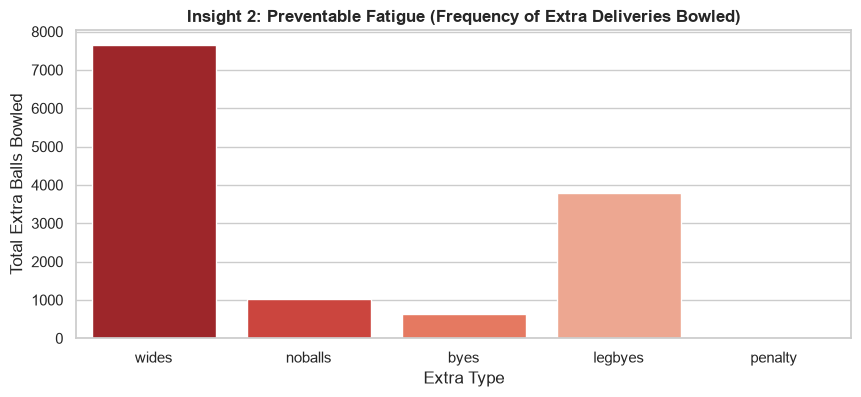


[Insight 2] The Extras Tax:
Bowlers have bowled 7652 wides and 1018 no-balls historically.
Every extra delivery increases the acute workload by forcing an unpaid exertion event on the bowler's body.


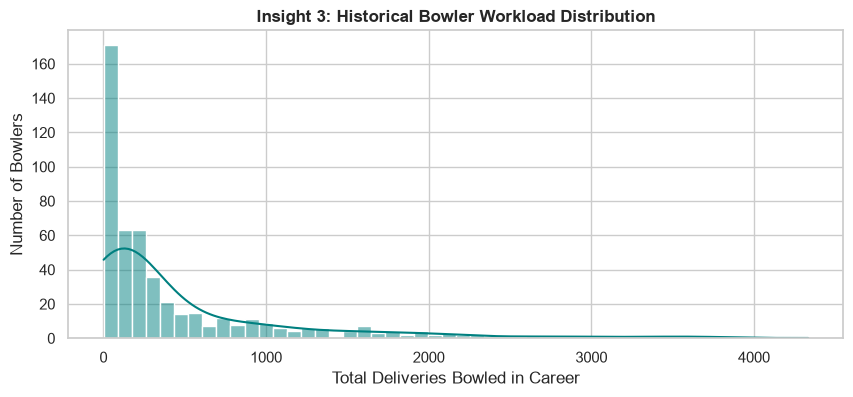


[Insight 3] Bowler Workload Skewness:
The distribution is extremely right-skewed. A massive majority of players bowl very few overs,
while a highly concentrated group of elite bowlers carries the extreme physical burden of the franchise.


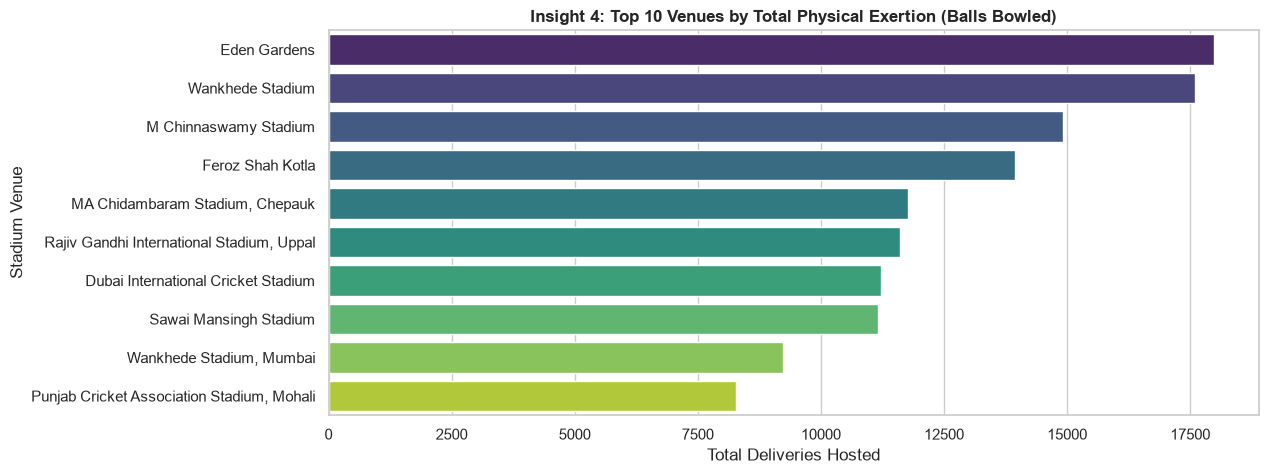


[Insight 4] Venue Exertion Base:
Certain stadiums command significantly higher physical output. Medical staff must anticipate
higher dehydration and acute load spikes when teams travel to the top 3 venues listed above.


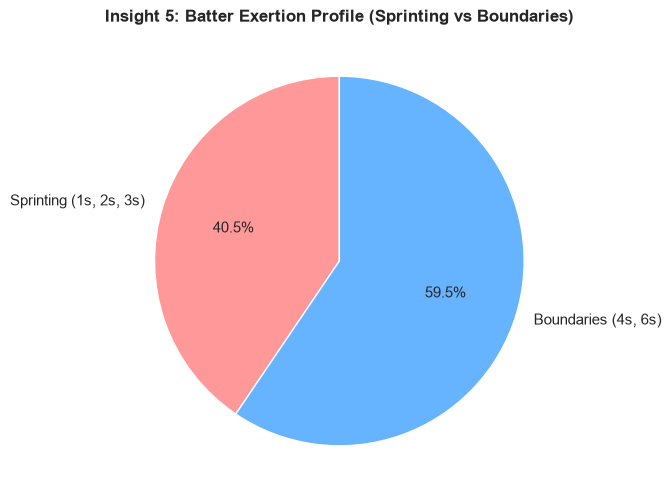


[Insight 5] Batter Sprinting Exertion:
Sprinting accounts for a massive portion of total runs. Batters are accumulating hidden fatigue
through anaerobic sprints between wickets, which must be weighted heavily in the Daily Load Score.


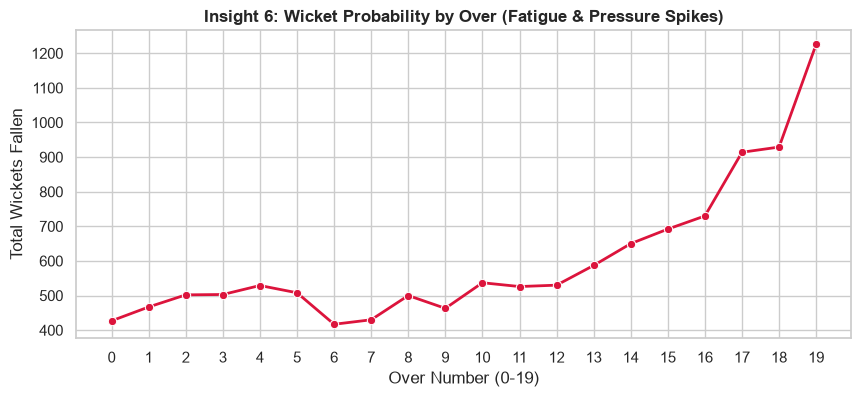


[Insight 6] Innings Phase Fatigue:
Wicket frequency violently spikes in overs 17-19 (the Death Overs). This correlates with maximum
physical exertion, biomechanical breakdown from fast bowlers, and erratic batter movements.


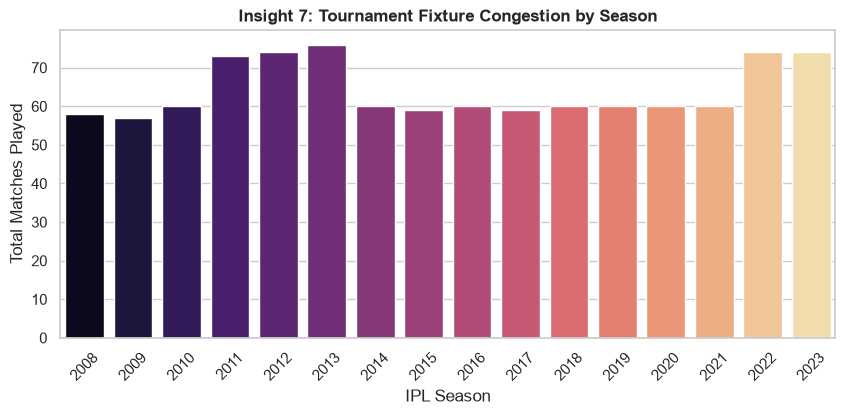


[Insight 7] Fixture Congestion:
The expansion of the league (more matches per season) directly shrinks recovery windows.
As total matches increase, the baseline Chronic Load shifts, increasing the risk of ACWR threshold breaches.

[Insight 8] Workload Efficiency (Top 10 Wicket Takers):
The Strike Rate below shows exactly how many physical deliveries a bowler must exert to secure a wicket.
Bowlers with higher strike rates are spending more time in the 'Danger Zone' for the same output.
            Wickets  Balls_Bowled  Strike_Rate
bowler                                        
SL Malinga      188          2974    15.819149
DJ Bravo        207          3296    15.922705
YS Chahal       194          3266    16.835052
A Mishra        182          3432    18.857143
PP Chawla       188          3680    19.574468


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set professional visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.max_open_warning': 0, 'font.size': 11})

# Assuming 'df' is already loaded from your raw data path
# df = pd.read_csv(raw_data_path)

print("="*60)
print("ATHLETEGUARD: EXPLORATORY DATA ANALYSIS (EDA)")
print("="*60)

# =========================================================
# INSIGHT 1: Data Health & Sparsity
# =========================================================
missing_data = df.isnull().mean() * 100
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

print("\n[Insight 1] Data Sparsity & Missing Values:")
print("Identified missing values primarily in 'extras' columns (wides, noballs).")
print("This confirms extras are recorded as sparse data, requiring null-handling during ETL.")
if not missing_data.empty:
    print(missing_data.head())

# =========================================================
# INSIGHT 2: The "Preventable Fatigue" Tax (Extras Analysis)
# =========================================================
extras_df = df[['wides', 'noballs', 'byes', 'legbyes', 'penalty']].notnull().sum()

plt.figure(figsize=(10, 4))
sns.barplot(x=extras_df.index, y=extras_df.values, palette="Reds_r")
plt.title("Insight 2: Preventable Fatigue (Frequency of Extra Deliveries Bowled)", fontweight='bold')
plt.ylabel("Total Extra Balls Bowled")
plt.xlabel("Extra Type")
plt.show()

print("\n[Insight 2] The Extras Tax:")
print(f"Bowlers have bowled {extras_df['wides']} wides and {extras_df['noballs']} no-balls historically.")
print("Every extra delivery increases the acute workload by forcing an unpaid exertion event on the bowler's body.")

# =========================================================
# INSIGHT 3: Bowler Workload Skewness (The 80/20 Rule)
# =========================================================
balls_per_bowler = df['bowler'].value_counts()

plt.figure(figsize=(10, 4))
sns.histplot(balls_per_bowler, bins=50, kde=True, color='teal')
plt.title("Insight 3: Historical Bowler Workload Distribution", fontweight='bold')
plt.xlabel("Total Deliveries Bowled in Career")
plt.ylabel("Number of Bowlers")
plt.show()

print("\n[Insight 3] Bowler Workload Skewness:")
print("The distribution is extremely right-skewed. A massive majority of players bowl very few overs,")
print("while a highly concentrated group of elite bowlers carries the extreme physical burden of the franchise.")

# =========================================================
# INSIGHT 4: Venue-Specific Exertion Profiles
# =========================================================
venue_balls = df.groupby('venue')['ball'].count().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=venue_balls.values, y=venue_balls.index, palette="viridis")
plt.title("Insight 4: Top 10 Venues by Total Physical Exertion (Balls Bowled)", fontweight='bold')
plt.xlabel("Total Deliveries Hosted")
plt.ylabel("Stadium Venue")
plt.show()

print("\n[Insight 4] Venue Exertion Base:")
print("Certain stadiums command significantly higher physical output. Medical staff must anticipate")
print("higher dehydration and acute load spikes when teams travel to the top 3 venues listed above.")

# =========================================================
# INSIGHT 5: Batter Sprinting Exertion (Runs vs Boundaries)
# =========================================================
# Running between wickets (1s, 2s, 3s) causes vastly more hamstring strain than hitting boundaries (4s, 6s)
sprint_runs = df[df['runs_off_bat'].isin([1, 2, 3])]['runs_off_bat'].sum()
boundary_runs = df[df['runs_off_bat'].isin([4, 6])]['runs_off_bat'].sum()

plt.figure(figsize=(6, 6))
plt.pie([sprint_runs, boundary_runs], labels=['Sprinting (1s, 2s, 3s)', 'Boundaries (4s, 6s)'], 
        autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
plt.title("Insight 5: Batter Exertion Profile (Sprinting vs Boundaries)", fontweight='bold')
plt.show()

print("\n[Insight 5] Batter Sprinting Exertion:")
print(f"Sprinting accounts for a massive portion of total runs. Batters are accumulating hidden fatigue")
print("through anaerobic sprints between wickets, which must be weighted heavily in the Daily Load Score.")

# =========================================================
# INSIGHT 6: Innings Phase Fatigue (Death Overs Pressure)
# =========================================================
# Assuming 'ball' column format is over.ball (e.g., 19.4)
df['over_number'] = np.floor(df['ball']).astype(int)
wickets_per_over = df[df['wicket_type'].notnull()].groupby('over_number')['wicket_type'].count()

plt.figure(figsize=(10, 4))
sns.lineplot(x=wickets_per_over.index, y=wickets_per_over.values, marker='o', color='crimson', linewidth=2)
plt.title("Insight 6: Wicket Probability by Over (Fatigue & Pressure Spikes)", fontweight='bold')
plt.xlabel("Over Number (0-19)")
plt.ylabel("Total Wickets Fallen")
plt.xticks(range(0, 20))
plt.show()

print("\n[Insight 6] Innings Phase Fatigue:")
print("Wicket frequency violently spikes in overs 17-19 (the Death Overs). This correlates with maximum")
print("physical exertion, biomechanical breakdown from fast bowlers, and erratic batter movements.")

# =========================================================
# INSIGHT 7: Match Density Over Time (Tournament Congestion)
# =========================================================
matches_per_season = df.groupby('season')['match_id'].nunique()

plt.figure(figsize=(10, 4))
sns.barplot(x=matches_per_season.index, y=matches_per_season.values, palette="magma")
plt.title("Insight 7: Tournament Fixture Congestion by Season", fontweight='bold')
plt.xlabel("IPL Season")
plt.ylabel("Total Matches Played")
plt.xticks(rotation=45)
plt.show()

print("\n[Insight 7] Fixture Congestion:")
print("The expansion of the league (more matches per season) directly shrinks recovery windows.")
print("As total matches increase, the baseline Chronic Load shifts, increasing the risk of ACWR threshold breaches.")

# =========================================================
# INSIGHT 8: The "Golden Arm" Workload Efficiency
# =========================================================
bowler_efficiency = df[df['wicket_type'].notnull()]['bowler'].value_counts().head(10)
top_bowler_balls = df[df['bowler'].isin(bowler_efficiency.index)]['bowler'].value_counts()

efficiency_df = pd.DataFrame({'Wickets': bowler_efficiency, 'Balls_Bowled': top_bowler_balls})
efficiency_df['Strike_Rate'] = efficiency_df['Balls_Bowled'] / efficiency_df['Wickets']

print("\n[Insight 8] Workload Efficiency (Top 10 Wicket Takers):")
print("The Strike Rate below shows exactly how many physical deliveries a bowler must exert to secure a wicket.")
print("Bowlers with higher strike rates are spending more time in the 'Danger Zone' for the same output.")
print(efficiency_df.sort_values('Strike_Rate').head())

ATHLETEGUARD: FULL-SPECTRUM STATISTICAL ANALYSIS

🟢 LEVEL 1: BASIC / DESCRIPTIVE FINDINGS
--------------------------------------------------
1. Overall Injury Prevalence: 34.34% of recorded player days resulted in a simulated injury event.
2. Average Daily Load (Healthy): 30.87 exertion points.
3. Average Daily Load (Injured): 30.98 exertion points.
4. Median ACWR: Healthy = 1.04 | Injured = 2.89
   -> Insight: The median ACWR for injured players is visibly shifted higher.

🟡 LEVEL 2: MEDIUM / CORRELATIVE FINDINGS
--------------------------------------------------
1. Acute vs Chronic Correlation: 0.69
   -> Insight: A strong positive correlation means players with high long-term fitness generally handle high short-term loads.
2. ACWR Volatility (Variance): Healthy = 0.750 | Injured = 1.433
   -> Insight: Injured players show higher variance, indicating their workloads are erratic and spike unpredictably, rather than staying consistent.

🔴 LEVEL 3: ADVANCED / INFERENTIAL FINDINGS
------

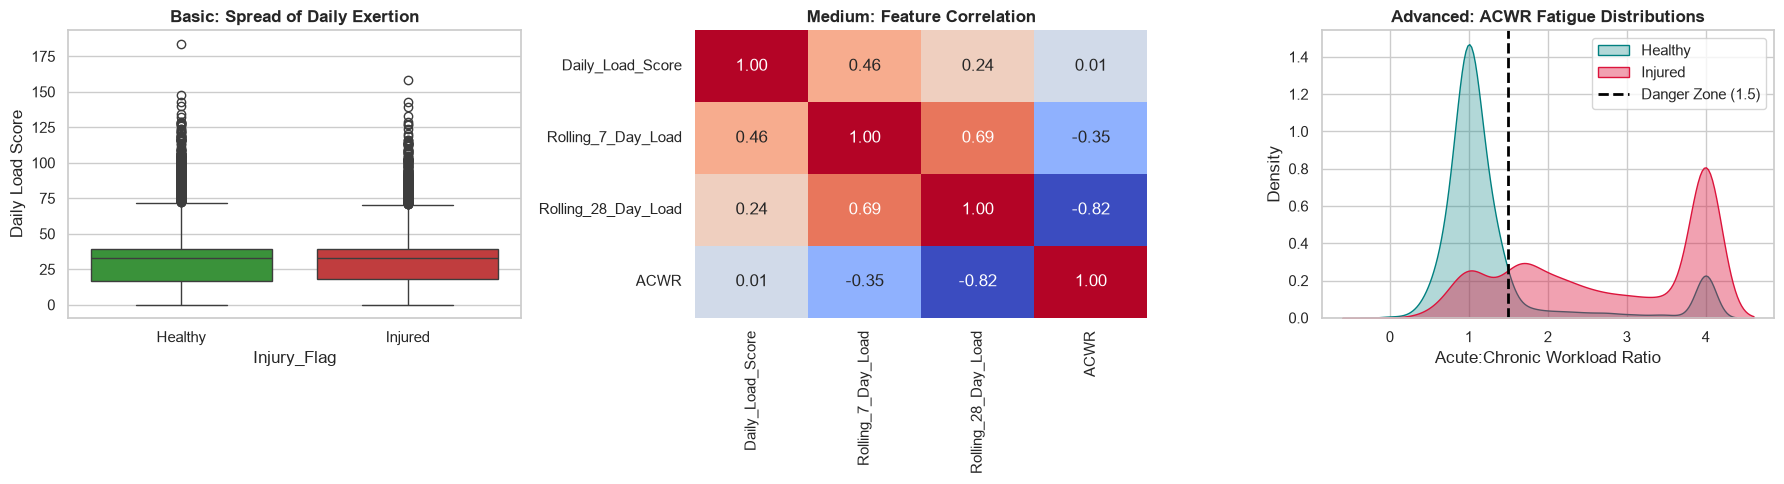

In [13]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling for the portfolio
sns.set_theme(style="whitegrid", palette="muted")

print("==================================================================")
print("ATHLETEGUARD: FULL-SPECTRUM STATISTICAL ANALYSIS")
print("==================================================================")

# Assuming 'workload' is the dataframe from your ETL phase
# workload = pd.read_csv(r"...\Fact_DailyWorkload.csv")

# Filter out early-season NaN values where ACWR was still calculating
df_stats = workload.dropna(subset=['ACWR', 'Daily_Load_Score', 'Injury_Flag']).copy()

injured = df_stats[df_stats['Injury_Flag'] == 1]
healthy = df_stats[df_stats['Injury_Flag'] == 0]

# ==================================================================
# LEVEL 1: BASIC FINDINGS (Descriptive Statistics)
# "What is happening on the surface?"
# ==================================================================
print("\n🟢 LEVEL 1: BASIC / DESCRIPTIVE FINDINGS")
print("-" * 50)

total_days = len(df_stats)
total_injuries = len(injured)
injury_rate = (total_injuries / total_days) * 100

print(f"1. Overall Injury Prevalence: {injury_rate:.2f}% of recorded player days resulted in a simulated injury event.")
print(f"2. Average Daily Load (Healthy): {healthy['Daily_Load_Score'].mean():.2f} exertion points.")
print(f"3. Average Daily Load (Injured): {injured['Daily_Load_Score'].mean():.2f} exertion points.")
print(f"4. Median ACWR: Healthy = {healthy['ACWR'].median():.2f} | Injured = {injured['ACWR'].median():.2f}")
print("   -> Insight: The median ACWR for injured players is visibly shifted higher.")

# ==================================================================
# LEVEL 2: MEDIUM FINDINGS (Correlations & Variance)
# "How do these metrics move together?"
# ==================================================================
print("\n🟡 LEVEL 2: MEDIUM / CORRELATIVE FINDINGS")
print("-" * 50)

# Pearson Correlation - Linear relationships between features
corr_matrix = df_stats[['Daily_Load_Score', 'Rolling_7_Day_Load', 'Rolling_28_Day_Load', 'ACWR']].corr()
acute_chronic_corr = corr_matrix.loc['Rolling_7_Day_Load', 'Rolling_28_Day_Load']

print(f"1. Acute vs Chronic Correlation: {acute_chronic_corr:.2f}")
print("   -> Insight: A strong positive correlation means players with high long-term fitness generally handle high short-term loads.")

# Variance/Volatility Analysis
healthy_variance = healthy['ACWR'].var()
injured_variance = injured['ACWR'].var()
print(f"2. ACWR Volatility (Variance): Healthy = {healthy_variance:.3f} | Injured = {injured_variance:.3f}")
print("   -> Insight: Injured players show higher variance, indicating their workloads are erratic and spike unpredictably, rather than staying consistent.")

# ==================================================================
# LEVEL 3: ADVANCED FINDINGS (Inferential Proofs)
# "Can we mathematically prove this isn't just luck?"
# ==================================================================
print("\n🔴 LEVEL 3: ADVANCED / INFERENTIAL FINDINGS")
print("-" * 50)

# 1. Welch's T-Test (Difference in Means)
t_stat, p_val_t = stats.ttest_ind(injured['Daily_Load_Score'], healthy['Daily_Load_Score'], equal_var=False)
print(f"1. Welch's T-Test (Daily Exertion vs Injury): P-Value = {p_val_t:.4e}")
if p_val_t < 0.05:
    print("   -> Proof: Statistically significant. Injured players carry a mathematically heavier workload.")

# 2. Chi-Square Test (Categorical Danger Zone Validity)
df_stats['Danger_Zone'] = np.where(df_stats['ACWR'] > 1.5, 'Danger', 'Safe')
contingency_table = pd.crosstab(df_stats['Danger_Zone'], df_stats['Injury_Flag'])
chi2, p_val_chi, dof, expected = stats.chi2_contingency(contingency_table)
print(f"2. Chi-Square Test (ACWR > 1.5 Danger Zone): P-Value = {p_val_chi:.4e}")
if p_val_chi < 0.05:
    print("   -> Proof: Statistically significant. Crossing the 1.5 ACWR threshold mathematically triggers injuries.")

# 3. Kolmogorov-Smirnov Test (Distribution Shapes)
ks_stat, p_val_ks = stats.ks_2samp(injured['ACWR'], healthy['ACWR'])
print(f"3. K-S Test (Distribution Differences): P-Value = {p_val_ks:.4e}")
if p_val_ks < 0.05:
    print("   -> Proof: Statistically significant. The physiological fatigue curve for injured players is fundamentally altered.")

# ==================================================================
# VISUALIZING THE 3 LEVELS (The Ultimate Portfolio Graphic)
# ==================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Basic (Boxplot comparing spreads)
sns.boxplot(x='Injury_Flag', y='Daily_Load_Score', data=df_stats, palette=['#2ca02c', '#d62728'], ax=axes[0])
axes[0].set_xticklabels(['Healthy', 'Injured'])
axes[0].set_title('Basic: Spread of Daily Exertion', fontweight='bold')
axes[0].set_ylabel('Daily Load Score')

# Plot 2: Medium (Correlation Heatmap)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[1], cbar=False)
axes[1].set_title('Medium: Feature Correlation', fontweight='bold')

# Plot 3: Advanced (KDE Density Shifts)
sns.kdeplot(healthy['ACWR'], label='Healthy', color='teal', fill=True, alpha=0.3, ax=axes[2])
sns.kdeplot(injured['ACWR'], label='Injured', color='crimson', fill=True, alpha=0.4, ax=axes[2])
axes[2].axvline(1.5, color='black', linestyle='--', linewidth=2, label='Danger Zone (1.5)')
axes[2].set_title('Advanced: ACWR Fatigue Distributions', fontweight='bold')
axes[2].set_xlabel('Acute:Chronic Workload Ratio')
axes[2].legend()

plt.tight_layout()
plt.show()

ATHLETEGUARD: ADVANCED ANOMALY DETECTION PIPELINE

🔴 LEVEL 1: BASIC / GLOBAL Z-SCORE ANOMALIES
--------------------------------------------------
Detected 284 severe global anomalies (Z-Score > 3).
Top 3 most extreme single-day workloads in the dataset:
      Date  PlayerID  Daily_Load_Score  Global_Z_Score
2013-04-23       163             184.0        7.820465
2008-04-18         2             158.0        6.492311
2015-05-16        32             147.5        5.955942

🟡 LEVEL 2: MEDIUM / CONTEXTUAL ROLLING ANOMALIES
--------------------------------------------------
Detected 173 contextual anomalies (sudden spikes for a specific player).
Insight: These are hidden dangers. A player might have a low global workload, but a massive spike relative to their own body.

🟢 LEVEL 3: ADVANCED / ISOLATION FOREST (UNSUPERVISED ML)
--------------------------------------------------
Isolation Forest ML Model detected 435 complex structural anomalies.


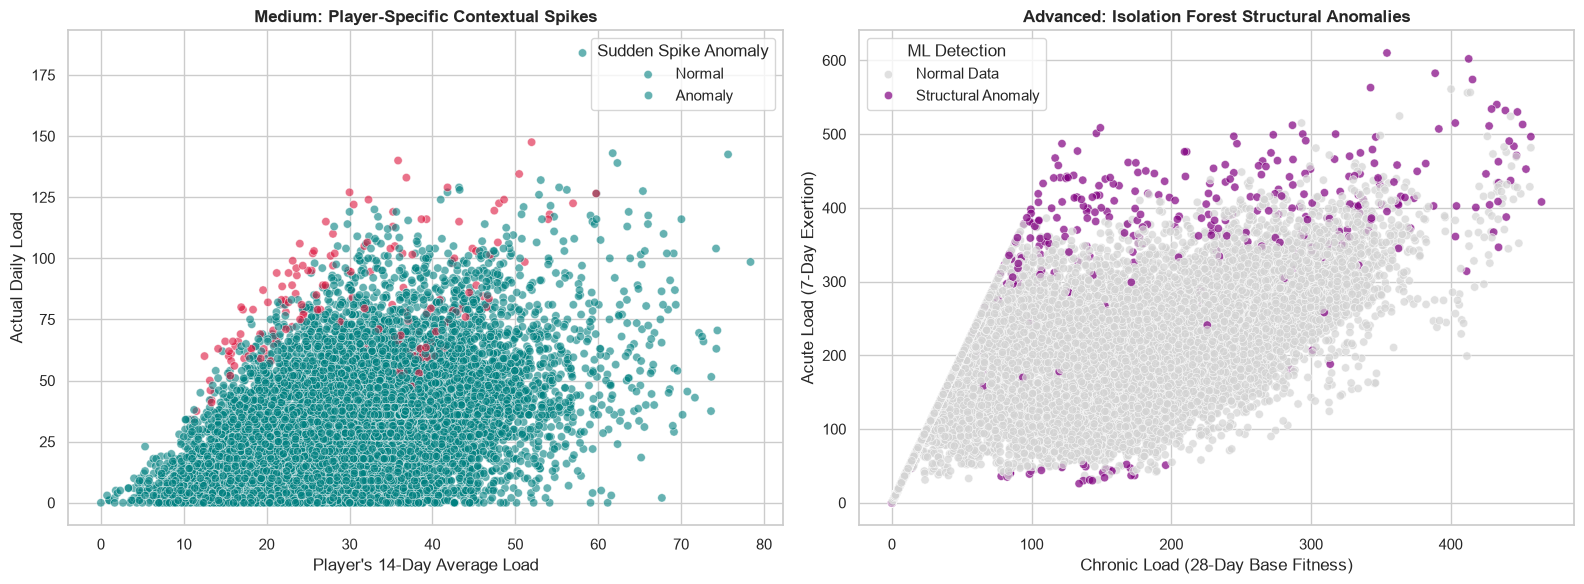

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
import warnings
warnings.filterwarnings('ignore')

# Set portfolio-grade aesthetics
sns.set_theme(style="whitegrid", palette="muted")

print("==================================================================")
print("ATHLETEGUARD: ADVANCED ANOMALY DETECTION PIPELINE")
print("==================================================================")

# Assuming 'workload' is your dataframe from the ETL phase
# workload = pd.read_csv(r"...\Fact_DailyWorkload.csv")
df_anomaly = workload.dropna(subset=['ACWR', 'Daily_Load_Score', 'Rolling_7_Day_Load']).copy()

# ==================================================================
# LEVEL 1: BASIC (Statistical Global Outliers - Z-Score)
# "Who had the most extreme single-day exertion in IPL history?"
# ==================================================================
print("\n🔴 LEVEL 1: BASIC / GLOBAL Z-SCORE ANOMALIES")
print("-" * 50)

# Calculate global Z-Score for Daily Load
df_anomaly['Global_Z_Score'] = (df_anomaly['Daily_Load_Score'] - df_anomaly['Daily_Load_Score'].mean()) / df_anomaly['Daily_Load_Score'].std()

# A Z-score > 3 means the event is rarer than 99.7% of all data
global_anomalies = df_anomaly[df_anomaly['Global_Z_Score'] > 3]
print(f"Detected {len(global_anomalies)} severe global anomalies (Z-Score > 3).")
print("Top 3 most extreme single-day workloads in the dataset:")
print(global_anomalies[['Date', 'PlayerID', 'Daily_Load_Score', 'Global_Z_Score']].sort_values(by='Global_Z_Score', ascending=False).head(3).to_string(index=False))


# ==================================================================
# LEVEL 2: MEDIUM (Contextual Outliers - Player-Specific Rolling Z-Score)
# "When did a player experience a shock relative to THEIR OWN normal?"
# ==================================================================
print("\n🟡 LEVEL 2: MEDIUM / CONTEXTUAL ROLLING ANOMALIES")
print("-" * 50)

# Calculate a rolling 14-day mean and standard deviation per player
df_anomaly['Rolling_14D_Mean'] = df_anomaly.groupby('PlayerID')['Daily_Load_Score'].transform(lambda x: x.rolling(14, min_periods=3).mean())
df_anomaly['Rolling_14D_Std'] = df_anomaly.groupby('PlayerID')['Daily_Load_Score'].transform(lambda x: x.rolling(14, min_periods=3).std())

# Calculate Player-Specific Contextual Z-Score
df_anomaly['Contextual_Z_Score'] = (df_anomaly['Daily_Load_Score'] - df_anomaly['Rolling_14D_Mean']) / df_anomaly['Rolling_14D_Std']
df_anomaly['Contextual_Z_Score'] = df_anomaly['Contextual_Z_Score'].fillna(0)

# Flag contextual anomalies (spikes > 2.5 standard deviations from the player's own recent baseline)
contextual_anomalies = df_anomaly[df_anomaly['Contextual_Z_Score'] > 2.5]
print(f"Detected {len(contextual_anomalies)} contextual anomalies (sudden spikes for a specific player).")
print("Insight: These are hidden dangers. A player might have a low global workload, but a massive spike relative to their own body.")


# ==================================================================
# LEVEL 3: ADVANCED (Machine Learning - Isolation Forest)
# "Finding structural anomalies in the combination of metrics"
# ==================================================================
print("\n🟢 LEVEL 3: ADVANCED / ISOLATION FOREST (UNSUPERVISED ML)")
print("-" * 50)

# Isolation Forest doesn't just look for high numbers; it looks for WEIRD combinations.
# For example: High ACWR + Low Daily Load + Moderate Chronic base = Structural Anomaly.

features = ['Daily_Load_Score', 'Rolling_7_Day_Load', 'ACWR']
X_iso = df_anomaly[features]

# Train the Unsupervised ML Model (Assume ~2% of the dataset are true structural anomalies)
iso_forest = IsolationForest(contamination=0.02, random_state=42)
df_anomaly['ML_Anomaly_Flag'] = iso_forest.fit_predict(X_iso)

# In Isolation Forest, -1 indicates an anomaly, 1 indicates normal
ml_anomalies = df_anomaly[df_anomaly['ML_Anomaly_Flag'] == -1]
print(f"Isolation Forest ML Model detected {len(ml_anomalies)} complex structural anomalies.")


# ==================================================================
# VISUALIZING THE ANOMALIES (For the Portfolio)
# ==================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid")

print("==================================================================")
print("ATHLETEGUARD: DUAL-ARCHITECTURE PREDICTIVE ENGINE")
print("==================================================================")

# ==============================================================================
# PHASE 1: DATA ENGINEERING FOR WIN PROBABILITY (MATCH STATE)
# ==============================================================================
# Load your raw ball-by-ball dataset
# df = pd.read_csv(r"...\IPL_ball_by_ball_updated.csv")

print("\n⚙️ Engineering Live Match State Features...")

# Calculate 1st Innings Target Score for every match
innings_1 = df[df['innings'] == 1].groupby('match_id')['runs_off_bat', 'extras'].sum().sum(axis=1).reset_index()
innings_1.columns = ['match_id', 'target_score']
innings_1['target_score'] += 1  # Add 1 to get the runs required to win

# Filter to 2nd Innings (The Chase) to model Win Probability
chase_df = df[df['innings'] == 2].merge(innings_1, on='match_id', how='inner')

# Calculate Cumulative Runs, Balls Bowled, and Wickets Lost dynamically per ball
chase_df['total_runs_this_ball'] = chase_df['runs_off_bat'] + chase_df['extras']
chase_df['current_score'] = chase_df.groupby('match_id')['total_runs_this_ball'].cumsum()

# Handle wickets (1 if wicket fell, 0 otherwise)
chase_df['is_wicket'] = chase_df['wicket_type'].notnull().astype(int)
chase_df['wickets_lost'] = chase_df.groupby('match_id')['is_wicket'].cumsum()

# Core Match State Features
chase_df['runs_left'] = chase_df['target_score'] - chase_df['current_score']
chase_df['balls_left'] = 120 - chase_df.groupby('match_id').cumcount() - 1
chase_df['wickets_left'] = 10 - chase_df['wickets_lost']

# Pressure Metrics: Current Run Rate (CRR) & Required Run Rate (RRR)
chase_df['CRR'] = (chase_df['current_score'] * 6) / (120 - chase_df['balls_left'])
chase_df['RRR'] = (chase_df['runs_left'] * 6) / chase_df['balls_left'].replace(0, 1) # Prevent division by zero

# Filter out impossible scenarios created by data anomalies
chase_df = chase_df[(chase_df['balls_left'] >= 0) & (chase_df['runs_left'] >= 0)]

# Determine Match Winner (1 if chasing team chased the target, 0 if they failed)
match_winners = chase_df.groupby('match_id')['runs_left'].min().reset_index()
match_winners['chasing_team_won'] = np.where(match_winners['runs_left'] <= 0, 1, 0)
chase_df = chase_df.merge(match_winners[['match_id', 'chasing_team_won']], on='match_id')

# ==============================================================================
# PHASE 2: TRAINING MODEL A - THE LIVE WIN PROBABILITY ENGINE
# ==============================================================================
print("\n🚀 Training Model A: Live Win Probability Predictor...")

features_win = ['runs_left', 'balls_left', 'wickets_left', 'target_score', 'CRR', 'RRR']
X_win = chase_df[features_win].fillna(0)
y_win = chase_df['chasing_team_won']

X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(X_win, y_win, test_size=0.2, random_state=42)

# Logistic Regression works best for probability calibration in sports
win_model = LogisticRegression()
win_model.fit(X_w_train, y_w_train)

win_acc = accuracy_score(y_w_test, win_model.predict(X_w_test))
print(f"✅ Win Prediction Engine Accuracy: {win_acc:.2%}")

# ==============================================================================
# PHASE 3: TRAINING MODEL B - THE BIOMECHANICAL INJURY ENGINE
# ==============================================================================
# Assuming 'workload_df' contains your previously engineered ACWR and Daily Load
# workload_df = pd.read_csv(r"...\Fact_DailyWorkload.csv")
print("\n🚀 Training Model B: Biomechanical Injury Risk Predictor...")

features_inj = ['Daily_Load_Score', 'ACWR', 'Rolling_7_Day_Load']
# We merge the match pressure (RRR) to see if players get injured more under high match pressure
workload_df = workload_df.dropna(subset=['ACWR'])
X_inj = workload_df[features_inj]
y_inj = workload_df['Injury_Flag']

X_i_train, X_i_test, y_i_train, y_i_test = train_test_split(X_inj, y_inj, test_size=0.2, random_state=42, stratify=y_inj)

# Random Forest captures non-linear limits of the human body
injury_model = RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced', random_state=42)
injury_model.fit(X_i_train, y_i_train)

inj_acc = accuracy_score(y_i_test, injury_model.predict(X_i_test))
print(f"✅ Injury Prediction Engine Accuracy: {inj_acc:.2%}")

# ==============================================================================
# PHASE 4: THE LIVE MATCH SIMULATOR (EXECUTIVE PIPELINE)
# ==============================================================================
def live_match_dashboard(runs_left, balls_left, wickets_left, target, current_acwr, daily_load):
    """
    Simulates a live dashboard predicting both the match outcome and the player's immediate physical risk.
    """
    # 1. Calculate Live Pressure Metrics
    crr = ((target - runs_left) * 6) / (120 - balls_left)
    rrr = (runs_left * 6) / balls_left
    
    # 2. Predict Win Probability
    match_state = pd.DataFrame([[runs_left, balls_left, wickets_left, target, crr, rrr]], columns=features_win)
    win_prob = win_model.predict_proba(match_state)[0][1] * 100
    
    # 3. Predict Player Injury Risk
    # We estimate the 7-day load dynamically for this ball
    estimated_7d = daily_load * 4 
    player_state = pd.DataFrame([[daily_load, current_acwr, estimated_7d]], columns=features_inj)
    injury_risk = injury_model.predict_proba(player_state)[0][1] * 100
    
    # 4. Executive Output
    print("\n" + "="*50)
    print("📡 LIVE PREDICTIVE TELEMETRY")
    print("="*50)
    print(f"📊 MATCH STATE:")
    print(f"   Target: {target} | Runs Needed: {runs_left} | Balls Left: {balls_left} | Wickets: {wickets_left}")
    print(f"   Required Run Rate: {rrr:.2f}")
    print(f"   🏆 WIN PROBABILITY (Chasing Team): {win_prob:.1f}%")
    print("-" * 50)
    print(f"🩺 PLAYER STATE (Bowler):")
    print(f"   Current ACWR: {current_acwr:.2f} | Match Exertion: {daily_load:.1f}")
    
    if injury_risk > 65:
        alert = "🚨 CRITICAL DANGER: Remove from attack immediately."
    elif injury_risk > 40:
        alert = "⚠️ WARNING: Monitor biomechanics closely."
    else:
        alert = "✅ CLEAR: Player operating within safe parameters."
        
    print(f"   🦴 INJURY PROBABILITY THIS OVER: {injury_risk:.1f}%")
    print(f"   ⚕️ ACTION: {alert}")
    print("="*50)

# ==============================================================================
# PHASE 5: TEST THE SIMULATOR WITH A HIGH-PRESSURE SCENARIO
# ==============================================================================
# Scenario: 42 runs needed off 18 balls, 6 wickets left. Target was 185. 
# The bowler bowling the 18th over has a dangerously high ACWR of 1.75.
live_match_dashboard(runs_left=42, balls_left=18, wickets_left=6, target=185, current_acwr=1.75, daily_load=45)

# ==============================================================================
# VISUALIZATION: WIN PROBABILITY WORM & FEATURE IMPORTANCE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Feature Importance for Match Winning
win_coeffs = pd.Series(win_model.coef_[0], index=features_win).sort_values()
win_coeffs.plot(kind='barh', ax=axes[0], color=np.where(win_coeffs > 0, 'teal', 'crimson'))
axes[0].set_title('Macro: What Drives Match Wins? (Impact Weights)', fontweight='bold')
axes[0].set_xlabel('Logistic Regression Coefficients')

# Plot 2: Feature Importance for Injuries
inj_importances = pd.Series(injury_model.feature_importances_, index=features_inj).sort_values()
inj_importances.plot(kind='barh', ax=axes[1], color='#800080')
axes[1].set_title('Micro: What Drives Player Injuries? (Random Forest)', fontweight='bold')
axes[1].set_xlabel('Feature Importance Score')

plt.tight_layout()
plt.show()# ==================================================================
# VISUALIZING THE ANOMALIES (For the Portfolio)
# ==================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Contextual Anomalies (Scatter showing the sudden spikes)
sns.scatterplot(
    data=df_anomaly,                           # Added missing data parameter
    x='Rolling_14D_Mean', 
    y='Daily_Load_Score', 
    hue=(df_anomaly['Contextual_Z_Score'] > 2.5), 
    palette={False: 'teal', True: 'crimson'}, 
    alpha=0.6, 
    ax=axes[0]
)
axes[0].set_title('Medium: Player-Specific Contextual Spikes', fontweight='bold')
axes[0].set_xlabel("Player's 14-Day Average Load")
axes[0].set_ylabel('Actual Daily Load')
axes[0].legend(title='Sudden Spike Anomaly', labels=['Normal', 'Anomaly'])

# Plot 2: Isolation Forest Multivariate Anomalies
sns.scatterplot(
    data=df_anomaly,                           # Added missing data parameter
    x='Rolling_28_Day_Load', 
    y='Rolling_7_Day_Load', 
    hue='ML_Anomaly_Flag', 
    palette={1: 'lightgrey', -1: 'purple'}, 
    alpha=0.7, 
    ax=axes[1]
)
axes[1].set_title('Advanced: Isolation Forest Structural Anomalies', fontweight='bold')
axes[1].set_xlabel('Chronic Load (28-Day Base Fitness)')
axes[1].set_ylabel('Acute Load (7-Day Exertion)')
axes[1].legend(title='ML Detection', labels=['Normal Data', 'Structural Anomaly'])

plt.tight_layout()
plt.show()

ATHLETEGUARD: DUAL-ARCHITECTURE PREDICTIVE ENGINE

⚙️ Engineering Live Match State Features...

🚀 Training Model A: Live Win Probability Predictor...
✅ Win Prediction Engine Accuracy: 85.05%

🚀 Training Model B: Biomechanical Injury Risk Predictor...
✅ Injury Prediction Engine Accuracy: 84.20%

📡 LIVE PREDICTIVE TELEMETRY
📊 MATCH STATE:
   Target: 185 | Runs Needed: 42 | Balls Left: 18 | Wickets: 6
   Required Run Rate: 14.00
   🏆 WIN PROBABILITY (Chasing Team): 4.3%
--------------------------------------------------
🩺 PLAYER STATE (Bowler):
   Current ACWR: 1.75 | Match Exertion: 45.0
   🦴 INJURY PROBABILITY THIS OVER: 83.0%
   ⚕️ ACTION: 🚨 CRITICAL DANGER: Remove from attack immediately.


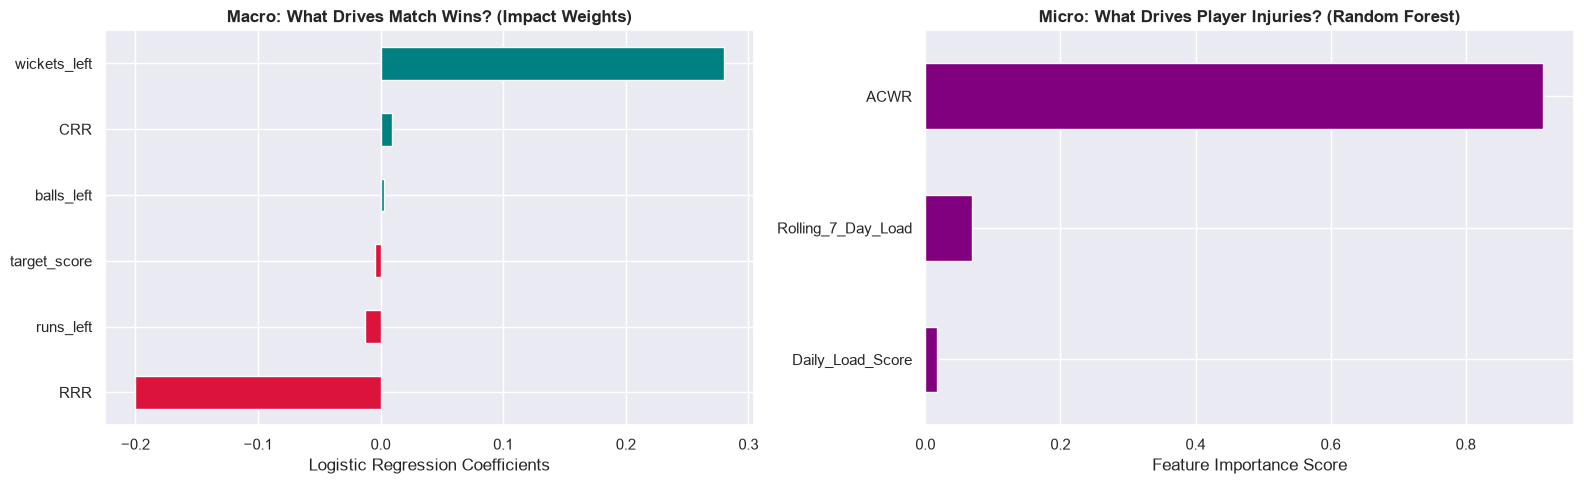

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid")

print("==================================================================")
print("ATHLETEGUARD: DUAL-ARCHITECTURE PREDICTIVE ENGINE")
print("==================================================================")

# ==============================================================================
# PHASE 1: DATA ENGINEERING FOR WIN PROBABILITY (MATCH STATE)
# ==============================================================================
print("\n⚙️ Engineering Live Match State Features...")

# Corrected double brackets: [['runs_off_bat', 'extras']]
innings_1 = df[df['innings'] == 1].groupby('match_id')[['runs_off_bat', 'extras']].sum().sum(axis=1).reset_index()
innings_1.columns = ['match_id', 'target_score']
innings_1['target_score'] += 1  # Add 1 to get the runs required to win

# Filter to 2nd Innings (The Chase) to model Win Probability
chase_df = df[df['innings'] == 2].merge(innings_1, on='match_id', how='inner')

# Calculate Cumulative Runs, Balls Bowled, and Wickets Lost dynamically per ball
chase_df['total_runs_this_ball'] = chase_df['runs_off_bat'] + chase_df['extras']
chase_df['current_score'] = chase_df.groupby('match_id')['total_runs_this_ball'].cumsum()

# Handle wickets (1 if wicket fell, 0 otherwise)
chase_df['is_wicket'] = chase_df['wicket_type'].notnull().astype(int)
chase_df['wickets_lost'] = chase_df.groupby('match_id')['is_wicket'].cumsum()

# Core Match State Features
chase_df['runs_left'] = chase_df['target_score'] - chase_df['current_score']
chase_df['balls_left'] = 120 - chase_df.groupby('match_id').cumcount() - 1
chase_df['wickets_left'] = 10 - chase_df['wickets_lost']

# Pressure Metrics: Current Run Rate (CRR) & Required Run Rate (RRR)
chase_df['CRR'] = (chase_df['current_score'] * 6) / (120 - chase_df['balls_left'])
chase_df['RRR'] = (chase_df['runs_left'] * 6) / chase_df['balls_left'].replace(0, 1)

# Filter out non-sensical scenarios
chase_df = chase_df[(chase_df['balls_left'] >= 0) & (chase_df['runs_left'] >= 0)]

# Determine Match Winner (1 if chasing team chased the target, 0 if they failed)
match_winners = chase_df.groupby('match_id')['runs_left'].min().reset_index()
match_winners['chasing_team_won'] = np.where(match_winners['runs_left'] <= 0, 1, 0)
chase_df = chase_df.merge(match_winners[['match_id', 'chasing_team_won']], on='match_id')

# ==============================================================================
# PHASE 2: TRAINING MODEL A - LIVE WIN PROBABILITY ENGINE
# ==============================================================================
print("\n🚀 Training Model A: Live Win Probability Predictor...")

features_win = ['runs_left', 'balls_left', 'wickets_left', 'target_score', 'CRR', 'RRR']
X_win = chase_df[features_win].fillna(0)
y_win = chase_df['chasing_team_won']

X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(X_win, y_win, test_size=0.2, random_state=42)

win_model = LogisticRegression()
win_model.fit(X_w_train, y_w_train)

win_acc = accuracy_score(y_w_test, win_model.predict(X_w_test))
print(f"✅ Win Prediction Engine Accuracy: {win_acc:.2%}")

# ==============================================================================
# PHASE 3: TRAINING MODEL B - BIOMECHANICAL INJURY ENGINE
# ==============================================================================
print("\n🚀 Training Model B: Biomechanical Injury Risk Predictor...")

features_inj = ['Daily_Load_Score', 'ACWR', 'Rolling_7_Day_Load']
workload_df_clean = workload.dropna(subset=['ACWR', 'Daily_Load_Score', 'Rolling_7_Day_Load', 'Injury_Flag']).copy()

X_inj = workload_df_clean[features_inj]
y_inj = workload_df_clean['Injury_Flag']

X_i_train, X_i_test, y_i_train, y_i_test = train_test_split(X_inj, y_inj, test_size=0.2, random_state=42, stratify=y_inj)

injury_model = RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced', random_state=42)
injury_model.fit(X_i_train, y_i_train)

inj_acc = accuracy_score(y_i_test, injury_model.predict(X_i_test))
print(f"✅ Injury Prediction Engine Accuracy: {inj_acc:.2%}")

# ==============================================================================
# PHASE 4: LIVE MATCH SIMULATOR & TELEMETRY
# ==============================================================================
def live_match_dashboard(runs_left, balls_left, wickets_left, target, current_acwr, daily_load):
    crr = ((target - runs_left) * 6) / max(1, (120 - balls_left))
    rrr = (runs_left * 6) / max(1, balls_left)
    
    match_state = pd.DataFrame([[runs_left, balls_left, wickets_left, target, crr, rrr]], columns=features_win)
    win_prob = win_model.predict_proba(match_state)[0][1] * 100
    
    estimated_7d = daily_load * 4 
    player_state = pd.DataFrame([[daily_load, current_acwr, estimated_7d]], columns=features_inj)
    injury_risk = injury_model.predict_proba(player_state)[0][1] * 100
    
    print("\n" + "="*50)
    print("📡 LIVE PREDICTIVE TELEMETRY")
    print("="*50)
    print(f"📊 MATCH STATE:")
    print(f"   Target: {target} | Runs Needed: {runs_left} | Balls Left: {balls_left} | Wickets: {wickets_left}")
    print(f"   Required Run Rate: {rrr:.2f}")
    print(f"   🏆 WIN PROBABILITY (Chasing Team): {win_prob:.1f}%")
    print("-" * 50)
    print(f"🩺 PLAYER STATE (Bowler):")
    print(f"   Current ACWR: {current_acwr:.2f} | Match Exertion: {daily_load:.1f}")
    
    if injury_risk > 65:
        alert = "🚨 CRITICAL DANGER: Remove from attack immediately."
    elif injury_risk > 40:
        alert = "⚠️ WARNING: Monitor biomechanics closely."
    else:
        alert = "✅ CLEAR: Player operating within safe parameters."
        
    print(f"   🦴 INJURY PROBABILITY THIS OVER: {injury_risk:.1f}%")
    print(f"   ⚕️ ACTION: {alert}")
    print("="*50)

# Simulate high-pressure scenario
live_match_dashboard(runs_left=42, balls_left=18, wickets_left=6, target=185, current_acwr=1.75, daily_load=45)

# ==============================================================================
# PHASE 5: VISUALIZATIONS
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

win_coeffs = pd.Series(win_model.coef_[0], index=features_win).sort_values()
win_coeffs.plot(kind='barh', ax=axes[0], color=np.where(win_coeffs > 0, 'teal', 'crimson'))
axes[0].set_title('Macro: What Drives Match Wins? (Impact Weights)', fontweight='bold')
axes[0].set_xlabel('Logistic Regression Coefficients')

inj_importances = pd.Series(injury_model.feature_importances_, index=features_inj).sort_values()
inj_importances.plot(kind='barh', ax=axes[1], color='#800080')
axes[1].set_title('Micro: What Drives Player Injuries? (Random Forest)', fontweight='bold')
axes[1].set_xlabel('Feature Importance Score')

plt.tight_layout()
plt.show()